# Eksplorujemy modele `text-to-speech`: `openai/tts-1` 

## Czym jest model `tts-1`?

* `tts-1` to model `text-to-speech` stworzony przez OpenAI.
* Generuje on dźwięk na podstawie tekstu.
* Działa w wielu językach.
* Możemy wybierać spośród wielu głosów
* [Dokumentacja](https://platform.openai.com/docs/guides/text-to-speech)  
* Wejście: tekst
* Wyjście: dźwięk


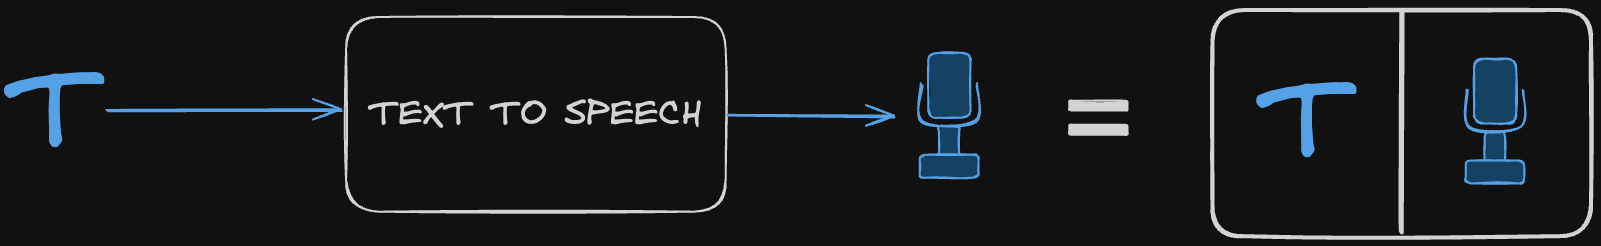

## Koszty

* Modele do generowania mowy są bardzo drogie!
* Koszt zależy od ilości znaków w tekście.

Przykładowe koszty:
* Jedna strona w książce na średnio `1800` znaków
* Książka ma `300` stron
* Ilość znaków w książce `300 * 1800 = 540.000`  
* Skoro za milion znaków płacimy `$15` to za całą książkę zapłacimy `0.54 * $15 = $8.1` (czyli około `32 PLN`)

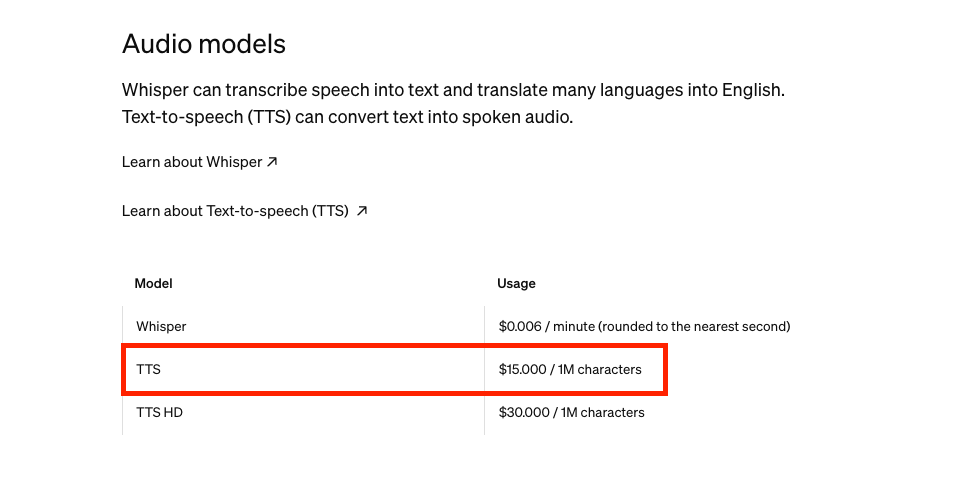

## Instalujemy wymagane biblioteki (conda wymagana)

- otwórz terminal
- uruchom `conda activate od_zera_do_ai`
- uruchom `conda install -y openai==1.47.0 python-dotenv`

In [ ]:
from dotenv import dotenv_values
from openai import OpenAI
from IPython.display import Audio

In [ ]:
env = dotenv_values(".env")

openai_client = OpenAI(api_key=env["OPENAI_API_KEY"])

## Jak używać modelu `tts-1`?

In [ ]:
response = openai_client.audio.speech.create(
    model="tts-1",
    voice="alloy",
    response_format="mp3",
    input="""
Sztuczna inteligencja to dziedzina technologii,
która umożliwia maszynom naśladowanie ludzkiego myślenia i podejmowania decyzji.

Dzięki zaawansowanym algorytmom i uczeniu maszynowemu, AI potrafi analizować ogromne ilości danych,
rozpoznawać wzorce i przewidywać przyszłe zdarzenia.

Współcześnie AI znajduje zastosowanie w wielu dziedzinach, takich jak medycyna, finanse,
transport czy edukacja, rewolucjonizując sposób, w jaki funkcjonują społeczeństwa.

Choć niesie ze sobą ogromny potencjał, rozwój AI rodzi także pytania o etykę,
prywatność i przyszłość rynku pracy.
    """,
)

In [ ]:
response.write_to_file("tts_1__alloy__audio_about_ai.mp3")

In [ ]:
Audio("tts_1__alloy__audio_about_ai.mp3")

## Zamykamy model w funkcji

In [ ]:
def generate_speech(text, voice, output_audio_path):
    response = openai_client.audio.speech.create(
        model="tts-1",
        voice=voice,
        response_format="mp3",
        input=text,
    )

    response.write_to_file(output_audio_path)
    return Audio(output_audio_path)

In [ ]:
generate_speech(
    text="""
Stoi na stacji lokomotywa,
Ciężka, ogromna i pot z niej spływa:
Tłusta oliwa.
Stoi i sapie, dyszy i dmucha,
Żar z rozgrzanego jej brzucha bucha:
Buch - jak gorąco!
Uch - jak gorąco!
Puff - jak gorąco!
Uff - jak gorąco!
Już ledwo sapie, już ledwo zipie,
A jeszcze palacz węgiel w nią sypie.
    """,
    voice="onyx",
    output_audio_path="tts_1__onyx__lokomotywa.mp3",
)

## Pomysły `gpt-4o` na użycie modelu

### 1. Audiobooki dla Dzieci
Model AI może przekształcać teksty bajek i opowiadań w audiobooki, które dzieci mogą słuchać przed snem. Można również dodać różne głosy dla różnych postaci, aby uczynić słuchanie bardziej interaktywnym i angażującym.

### 2. Audioguidy po Muzeach i Galeriach Sztuki
AI może przekształcać opisy eksponatów w muzeach lub galeriach w narrację, którą odwiedzający mogą słuchać przez słuchawki. Dzięki temu zwiedzający mogą zyskać głębsze zrozumienie kontekstu i historii każdego eksponatu.

### 3. Wsparcie Dla Osób Niewidomych i Słabowidzących
Model TTS może być używany do odczytywania tekstów z dokumentów, stron internetowych, e-maili czy książek dla osób niewidomych lub słabowidzących, ułatwiając im dostęp do informacji i treści.

### 4. Automatyczne Odczytywanie Powiadomień na Urządzeniach Mobilnych
TTS może odczytywać powiadomienia, wiadomości tekstowe, e-maile i inne ważne informacje na urządzeniach mobilnych, co jest szczególnie przydatne w sytuacjach, gdy użytkownik nie może bezpośrednio spojrzeć na ekran (np. podczas jazdy samochodem).

### 5. Narracja Dla Filmów Instruktażowych i Kursów Online
Twórcy kursów online i tutoriali mogą używać AI do generowania profesjonalnej narracji na podstawie tekstów instrukcji. TTS może tworzyć nagrania audio dla prezentacji, co pozwala na szybsze tworzenie wysokiej jakości materiałów edukacyjnych.

### 6. Tworzenie Podcastów na Podstawie Artykułów
Model TTS może przekształcać artykuły blogowe, newsy lub inne treści pisane w nagrania audio, które następnie mogą być publikowane jako podcasty. To umożliwia użytkownikom konsumpcję treści w trakcie innych czynności, np. podczas jazdy samochodem czy ćwiczeń.

### 7. Personalizowane Wiadomości Głosowe
Użytkownicy mogą wprowadzać tekst, który następnie jest przekształcany w wiadomość głosową. Może to być używane do personalizowanych życzeń urodzinowych, automatycznych odpowiedzi w systemach CRM, czy nawet do głosowych powiadomień w aplikacjach mobilnych.

### 8. Odczytywanie Książek Naukowych i Artykułów dla Studentów
TTS może przekształcać podręczniki, artykuły naukowe i inne materiały edukacyjne w format audio, który studenci mogą słuchać, ucząc się w ruchu lub przyswajając trudne materiały w bardziej przystępny sposób.

### 9. Asystent Głosowy Do Samochodów
Model TTS może być używany w samochodach do odczytywania nawigacji, powiadomień, przypomnień i innych informacji w czasie rzeczywistym, co umożliwia kierowcy skupienie się na drodze bez potrzeby spoglądania na ekran.

### 10. Tworzenie Multimedialnych Książek Do Nauki Języków Obcych
AI może przekształcać teksty w obcym języku w nagrania audio, które są synchronizowane z tekstem. Dzięki temu użytkownicy mogą czytać i jednocześnie słuchać prawidłowej wymowy, co wspiera efektywną naukę języków obcych.